# Actividad Grupal #3 – Demo integradora con IA

## Análisis de comunidades en una red de transacciones de Ethereum

### Objetivo del proyecto

El objetivo de esta demo es analizar la estructura de una red
de transacciones de Ethereum mediante algoritmos de grafos
e inteligencia artificial generativa.

Se reutiliza el conjunto de datos de las actividades grupales
anteriores y se aplican dos técnicas principales:

1. **Louvain:** para identificar comunidades de direcciones
   a partir de sus conexiones.
2. **PageRank:** para determinar la importancia estructural
   de las direcciones dentro de la red.

Posteriormente, se seleccionan las diez direcciones con mayor
PageRank de la comunidad más grande y se utiliza ChatGPT
como asistente para interpretar sus posibles características.

Las interpretaciones generadas por IA se evalúan críticamente,
diferenciando los resultados verificables de las hipótesis
que requieren información adicional.

### Herramientas utilizadas

- Python
- Pandas
- NetworkX
- Matplotlib
- ChatGPT (IA generativa)

### 1. Carga y exploración de los datos

En esta primera etapa se importa el conjunto de transacciones
desde el archivo `transactions.csv` y se examinan su cantidad
de registros, sus columnas y sus primeras filas.

In [1]:

import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

df = pd.read_csv("transactions.csv")

print("Cantidad de transacciones:", len(df))
print("Columnas disponibles:", df.columns.tolist())

display(df.head())


Cantidad de transacciones: 5000
Columnas disponibles: ['from_address', 'to_address', 'block_number', 'transaction_hash', 'value']


,from_address,to_address,block_number,transaction_hash,value
0,0xccdc7f38760f152bbae4d97f7cf0330b1e89926c,0x3fc91a3afd70395cd496c647d5a6cc9d4b2b7fad,18000045,0x9756166f739aac19031ee4a040eb1177c3b42299d181...,10000000000000000
1,0x82f70c57b46389af79c058161f3c82379a040b23,0x7a250d5630b4cf539739df2c5dacb4c659f2488d,18000045,0xe7ff7d9356fb261474291b752f0b32e0cb3eefc15277...,100000000000000000
2,0x00f4c02ae927bc55ae713dabb4495f7d8924898e,0x255958ae66431cae0a2aafd19a3102b3cf08f411,18000045,0x065a6875f60d4b2b644fb7630334e21ae1993e28d12c...,40000000000000000
3,0x6f89b67052e88f60d238997909a8e22fc27f31f5,0x7a250d5630b4cf539739df2c5dacb4c659f2488d,18000045,0x431c9dccb21e4e888a79fbf9d12f1970fedd08db8913...,100000000000000000
4,0x5a63b56d3b3c43542246b4e788ef26465e34f5c8,0x1e4a1c7b3ec4e73ef98d4c086d9258017ad1d4ac,18000045,0x1b786691fc1734fccd917184c705f9b571b1f01dec5e...,4792810000000000


### Control de reproducibilidad y procedencia de los datos

Para garantizar la reproducibilidad del análisis, se utiliza una semilla aleatoria fija de valor 42 y se documentan las versiones de las bibliotecas empleadas.

Además, se calcula el hash SHA-256 del archivo `transactions.csv`, lo que permite verificar la integridad del conjunto de datos y confirmar que los resultados corresponden al mismo archivo.

El análisis se realiza sobre una muestra de 5.000 transacciones de Ethereum. Las métricas de centralidad y la detección de comunidades permiten estudiar su estructura, pero no identificar de manera definitiva a los propietarios de las direcciones.

In [2]:
# con esta porcion de codigo, cualquier persona que abra el 
# notebook pueda comprobar qué  datos se utilizaron, con qué
# versiones se ejecutó y cómo se controló la reproducibilidad

import hashlib
import random
import sys
import numpy as np
from pathlib import Path

# Semilla fija para reproducibilidad
SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)

# Verificación del dataset
archivo_datos = Path("transactions.csv")

assert archivo_datos.is_file(), "No se encuentra transactions.csv"
assert len(df) == 5000, "Cantidad de registros inesperada"
assert {"from_address", "to_address"}.issubset(df.columns)

# Identificación de valores faltantes
faltantes = df[["from_address", "to_address"]].isna().sum()

print("Valores faltantes:")
print(faltantes)

# Evitar procesar dos veces la misma transacción
df_sin_duplicados = df.drop_duplicates(
    subset=["transaction_hash"],
    keep="first"
).copy()

# Excluir transacciones sin direcciones completas
df_aristas = df_sin_duplicados.dropna(
    subset=["from_address", "to_address"]
).copy()

print("Transacciones originales:", len(df))
print("Transacciones con ambas direcciones:", len(df_aristas))
print("Registros excluidos:", len(df) - len(df_aristas))

# Registrar integridad y versiones
hash_dataset = hashlib.sha256(
    archivo_datos.read_bytes()
).hexdigest()

print("\nSHA-256 del dataset:", hash_dataset)
print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("NetworkX:", nx.__version__)
print("NumPy:", np.__version__)
print("Semilla:", SEMILLA)



Valores faltantes:
from_address    0
to_address      1
dtype: int64
Transacciones originales: 5000
Transacciones con ambas direcciones: 4999
Registros excluidos: 1

SHA-256 del dataset: 712bb757578f5430f2d67b5f8d445a057041bf2c011c835a730df863599fc2ab
Python: 3.13.15
Pandas: 3.0.5
NetworkX: 3.6.1
NumPy: 2.5.2
Semilla: 42


### 2. Construcción del grafo de transacciones

A partir del conjunto de datos, se construye un grafo
dirigido utilizando la biblioteca NetworkX.

Cada nodo representa una dirección de Ethereum y cada
arista dirigida representa una relación transaccional
desde una dirección de origen hacia una de destino.

Cuando existen múltiples transacciones entre el mismo
par de direcciones, se incrementa el peso de la arista
correspondiente en lugar de crear conexiones duplicadas.

Esta representación permite analizar la estructura de
la red, calcular métricas de centralidad y detectar
comunidades de direcciones.

In [3]:
# Construir el grafo dirigido de Ethereum
G = nx.DiGraph()

# Incorporar únicamente transacciones con direcciones válidas
for _, fila in df_aristas.iterrows():
    origen = fila["from_address"]
    destino = fila["to_address"]

    if G.has_edge(origen, destino):
        G[origen][destino]["weight"] += 1
    else:
        G.add_edge(origen, destino, weight=1)

# Mostrar las características de la red
print("ANÁLISIS DE LA RED DE ETHEREUM")
print("-----------------------------")
print("Cantidad de nodos:", G.number_of_nodes())
print("Cantidad de aristas únicas:", G.number_of_edges())
print("Cantidad de transacciones originales:", len(df))
print("Cantidad de transacciones utilizadas:", len(df_aristas))
print("Tipo de grafo:", type(G).__name__)

ANÁLISIS DE LA RED DE ETHEREUM
-----------------------------
Cantidad de nodos: 5620
Cantidad de aristas únicas: 4601
Cantidad de transacciones originales: 5000
Cantidad de transacciones utilizadas: 4999
Tipo de grafo: DiGraph


In [4]:

# CENTRALIDAD DE GRADO

# Calcular conexiones y transacciones entrantes
grados_entrada = pd.DataFrame({
    "Cuenta": list(G.nodes()),
    "Conexiones": [G.in_degree(n) for n in G.nodes()],
    "Transacciones": [
        G.in_degree(n, weight="weight") for n in G.nodes()
    ]
})

# Calcular conexiones y transacciones salientes
grados_salida = pd.DataFrame({
    "Cuenta": list(G.nodes()),
    "Conexiones": [G.out_degree(n) for n in G.nodes()],
    "Transacciones": [
        G.out_degree(n, weight="weight") for n in G.nodes()
    ]
})

# Seleccionar los 5 nodos principales
top_entrada = grados_entrada.sort_values(
    by=["Conexiones", "Transacciones"],
    ascending=False
).head(5)

top_salida = grados_salida.sort_values(
    by=["Conexiones", "Transacciones"],
    ascending=False
).head(5)

print("TOP 5 - GRADO DE ENTRADA")
display(top_entrada)

print("TOP 5 - GRADO DE SALIDA")
display(top_salida)


TOP 5 - GRADO DE ENTRADA


,Cuenta,Conexiones,Transacciones
1,0x3fc91a3afd70395cd496c647d5a6cc9d4b2b7fad,460,565
3,0x7a250d5630b4cf539739df2c5dacb4c659f2488d,321,387
159,0x28c6c06298d514db089934071355e5743bf21d60,106,106
211,0xe49b2f0467f69fb0cbccadda167c48b1d95856d0,84,84
183,0x58df81babdf15276e761808e872a3838cbecbcf9,51,55


TOP 5 - GRADO DE SALIDA


,Cuenta,Conexiones,Transacciones
22,0x4976a4a02f38326660d17bf34b431dc6e2eb2327,47,47
30,0xdfd5293d8e347dfe59e90efd55b2956a1343963d,43,43
159,0x28c6c06298d514db089934071355e5743bf21d60,41,41
108,0x9696f59e4d72e237be84ffd425dcad154bf96976,38,38
61,0x21a31ee1afc51d94c2efccaa2092ad1028285549,37,37


In [5]:


# CENTRALIDAD PAGERANK

# Calcular PageRank sobre las conexiones dirigidas
# Usamos weight=None para analizar conexiones únicas,
# sin multiplicar la importancia por transacciones repetidas.
pagerank = nx.pagerank(
    G,
    alpha=0.85,
    weight=None,
    max_iter=200,
    tol=1e-06
)

# Crear una tabla con los resultados
tabla_pagerank = pd.DataFrame(
    pagerank.items(),
    columns=["Cuenta", "PageRank"]
)

# Ordenar de mayor a menor y obtener los 5 principales
top_pagerank = tabla_pagerank.sort_values(
    by="PageRank",
    ascending=False
).head(5)

print("TOP 5 - CENTRALIDAD PAGERANK")
display(top_pagerank)

# Comprobar que los valores sumen aproximadamente 1
print("Suma total de PageRank:", sum(pagerank.values()))



TOP 5 - CENTRALIDAD PAGERANK


,Cuenta,PageRank
1,0x3fc91a3afd70395cd496c647d5a6cc9d4b2b7fad,0.043135
3,0x7a250d5630b4cf539739df2c5dacb4c659f2488d,0.028141
159,0x28c6c06298d514db089934071355e5743bf21d60,0.010992
24,0xf7858da8a6617f7c6d0ff2bcafdb6d2eedf64840,0.010178
211,0xe49b2f0467f69fb0cbccadda167c48b1d95856d0,0.007643


Suma total de PageRank: 1.0000000000000124


In [6]:

# CENTRALIDAD DE INTERMEDIACIÓN

print("Calculando Betweenness...")
print("Este cálculo puede tardar varios minutos.")

# Calcular intermediación exacta
betweenness = nx.betweenness_centrality(
    G,
    normalized=True,
    weight=None
)

# Crear una tabla con los resultados
tabla_betweenness = pd.DataFrame(
    betweenness.items(),
    columns=["Cuenta", "Betweenness"]
)

# Seleccionar los 5 nodos principales
top_betweenness = tabla_betweenness.sort_values(
    by="Betweenness",
    ascending=False
).head(5)

print("TOP 5 - CENTRALIDAD DE INTERMEDIACIÓN")
display(top_betweenness)


Calculando Betweenness...
Este cálculo puede tardar varios minutos.
TOP 5 - CENTRALIDAD DE INTERMEDIACIÓN


,Cuenta,Betweenness
159,0x28c6c06298d514db089934071355e5743bf21d60,0.000351
51,0xcbd6832ebc203e49e2b771897067fce3c58575ac,0.000160
294,0x974caa59e49682cda0ad2bbe82983419a2ecc400,0.000124
4634,0xf1c6a313058db7f8f4329975ee1d9f096389a021,0.000121
3054,0xfe912c94f0249dba80849019f508f46a642d343c,0.000078


In [7]:

# DETECCIÓN DE COMUNIDADES CON LOUVAIN

# Louvain trabaja con una versión no dirigida
# del grafo, porque analizamos grupos de conexiones.
G_comunidades = nx.Graph()

# Agregar las conexiones únicas del grafo original
G_comunidades.add_nodes_from(G.nodes())
G_comunidades.add_edges_from(G.edges())

# Detectar comunidades con Louvain
comunidades = nx.community.louvain_communities(
    G_comunidades,
    weight=None,
    resolution=1,
    seed=42
)

# Ordenar las comunidades por tamaño
comunidades = sorted(
    comunidades,
    key=len,
    reverse=True
)

# Mostrar resultados
print("DETECCIÓN DE COMUNIDADES - LOUVAIN")
print("---------------------------------")
print("Cantidad total de comunidades:", len(comunidades))

print("\nTOP 5 - COMUNIDADES MÁS GRANDES")

for i, comunidad in enumerate(comunidades[:5], start=1):
    print(f"Comunidad {i}: {len(comunidad)} nodos")


DETECCIÓN DE COMUNIDADES - LOUVAIN
---------------------------------
Cantidad total de comunidades: 1188

TOP 5 - COMUNIDADES MÁS GRANDES
Comunidad 1: 467 nodos
Comunidad 2: 357 nodos
Comunidad 3: 168 nodos
Comunidad 4: 141 nodos
Comunidad 5: 134 nodos


In [8]:
# Ordenar las comunidades de mayor a menor tamaño
comunidades_ordenadas = sorted(
    comunidades,
    key=len,
    reverse=True
)

# Mostrar las cinco comunidades más grandes
for i, comunidad in enumerate(comunidades_ordenadas[:5], start=1):
    print(f"Comunidad {i}: {len(comunidad)} nodos")

Comunidad 1: 467 nodos
Comunidad 2: 357 nodos
Comunidad 3: 168 nodos
Comunidad 4: 141 nodos
Comunidad 5: 134 nodos


In [9]:
# Seleccionar la comunidad más grande
comunidad_principal = comunidades_ordenadas[0]

# Seleccionar los nodos de esa comunidad
pagerank_comunidad = {
    nodo: pagerank[nodo]
    for nodo in comunidad_principal
    if nodo in pagerank
}

# Ordenar los nodos por PageRank de mayor a menor.
# Si dos nodos tienen el mismo PageRank,
# se ordenan alfabéticamente por dirección.

top_10_comunidad = sorted(
    pagerank_comunidad.items(),
    key=lambda x: (-x[1], x[0])
)[:10]

# Mostrar las 10 direcciones principales
print("Top 10 nodos de la comunidad principal:\n")

for posicion, (nodo, valor) in enumerate(top_10_comunidad, start=1):
    print(f"{posicion}. Dirección: {nodo} | PageRank: {valor:.8f}")

Top 10 nodos de la comunidad principal:

1. Dirección: 0x3fc91a3afd70395cd496c647d5a6cc9d4b2b7fad | PageRank: 0.04313483
2. Dirección: 0x03f7724180aa6b939894b5ca4314783b0b36b329 | PageRank: 0.00032949
3. Dirección: 0xbe7be3071a9c9e482f741c4ec5b3cae952506df5 | PageRank: 0.00030267
4. Dirección: 0xc26ba6596c7879772b29b77b0a8f8b0d8a580ca7 | PageRank: 0.00027054
5. Dirección: 0x0167606b5835ae49837f860eeec5636622260dda | PageRank: 0.00023134
6. Dirección: 0x5645c84f4281aad49a908de558fb5094f78f649b | PageRank: 0.00019488
7. Dirección: 0x58bcf765d22a7bad08b19e405f206baa8b23bfa2 | PageRank: 0.00019488
8. Dirección: 0x644695f58bb9b837a6c4238ac65a42303bac5bb2 | PageRank: 0.00019488
9. Dirección: 0x7207b4b7789543b4cb7b58f25636852b6eb0ff3a | PageRank: 0.00019488
10. Dirección: 0x73754f5805e1aba1d94226905b7a1c976cb7250e | PageRank: 0.00019488


In [10]:
# Verificación de la selección de nodos principales

assert len(comunidad_principal) == 467

assert len(top_10_comunidad) == 10

assert top_10_comunidad == sorted(
    top_10_comunidad,
    key=lambda x: (-x[1], x[0])
)

assert top_10_comunidad[0][0] == (
    "0x3fc91a3afd70395cd496c647d5a6cc9d4b2b7fad"
)

print("Controles de consistencia: OK")

Controles de consistencia: OK


## Análisis de comunidades mediante inteligencia artificial

En esta etapa utilizaremos ChatGPT como herramienta de
inteligencia artificial generativa para interpretar los
resultados obtenidos mediante el algoritmo Louvain.

Seleccionamos la comunidad más grande, compuesta por
467 nodos, e identificamos sus diez direcciones principales
según el valor de PageRank.

El objetivo es analizar posibles patrones de comportamiento,
formular hipótesis sobre la función de estas direcciones
y reconocer las limitaciones del análisis.

### Consulta realizada a ChatGPT

Se utilizó ChatGPT como asistente de inteligencia artificial
generativa para interpretar los resultados del análisis de redes.

Se le proporcionaron las diez direcciones principales de
la comunidad de 467 nodos, junto con sus respectivos
valores de PageRank.

La consulta solicitó responder las siguientes preguntas:

1. ¿Qué características podrían tener en común estas direcciones?
2. ¿Podrían estar relacionadas con un exchange, un juego
   blockchain, una aplicación descentralizada o usuarios
   particulares?
3. ¿Qué significa que la primera dirección tenga un PageRank
   considerablemente superior?
4. ¿Qué información adicional necesitaríamos para identificar
   la función de estas direcciones?
5. ¿Cuáles son las limitaciones y riesgos de utilizar
   inteligencia artificial generativa para interpretar estos
   resultados?

También se indicó explícitamente al modelo que diferenciara
los hechos respaldados por datos de las hipótesis y que no
inventara identidades ni relaciones entre direcciones.

### Resultados obtenidos mediante ChatGPT

Se proporcionaron a ChatGPT las diez direcciones principales
de la comunidad más grande, compuesta por 467 nodos,
seleccionadas mediante PageRank descendente y orden
alfabético como criterio secundario para resolver empates.

El modelo identificó que las direcciones comparten su
pertenencia a una misma comunidad estructural, aunque esto
no demuestra que estén administradas por una misma entidad
ni que desarrollen actividades similares.

La primera dirección, 0x3fc91a..., presentó un PageRank
considerablemente superior al de las restantes. La
comparación realizada mediante Python confirmó que su
valor es aproximadamente 130,92 veces el de la segunda.

ChatGPT propuso distintas hipótesis sobre la posible
función de las direcciones, como exchanges, aplicaciones
descentralizadas, juegos blockchain y usuarios particulares.

Sin embargo, señaló que ninguna de estas posibilidades
puede confirmarse únicamente mediante PageRank y Louvain.

También advirtió que las direcciones con valores iguales
de PageRank no necesariamente tienen funciones similares.

Para validar las hipótesis sería necesario analizar
historiales de transacciones, grados de entrada y salida,
contratos inteligentes y etiquetas públicas verificadas.

Por lo tanto, las interpretaciones generadas por IA se
consideran exploratorias y requieren validación adicional.

### Trazabilidad de la interacción con ChatGPT

La interpretación presentada se fundamenta en una respuesta de ChatGPT obtenida durante el desarrollo del proyecto, a partir de las diez direcciones principales de la comunidad de 467 nodos.

La respuesta original distinguió los hechos observables de las hipótesis sobre posibles funciones de las direcciones y advirtió que Louvain y PageRank no permiten establecer identidades ni actividades específicas.

La consulta original utilizó valores de PageRank anteriores a la corrección del tratamiento de datos faltantes. Posteriormente, se recalcularon las métricas y se verificó que las conclusiones cualitativas continuaran siendo compatibles con los resultados actualizados.

El informe IMRaD presenta una síntesis de la interpretación original, no una transcripción literal. La respuesta completa se conserva en el archivo Respuesta_Original_ChatGPT.pdf, como evidencia de la interacción con inteligencia artificial generativa.

In [11]:
# Verificar la diferencia de PageRank entre los dos nodos principales

primer_nodo = top_10_comunidad[0]
segundo_nodo = top_10_comunidad[1]

relacion_pagerank = primer_nodo[1] / segundo_nodo[1]

print("PageRank del primer nodo:", round(primer_nodo[1], 8))
print("PageRank del segundo nodo:", round(segundo_nodo[1], 8))
print(f"El primer nodo tiene un PageRank {relacion_pagerank:.2f} veces mayor que el segundo.")

PageRank del primer nodo: 0.04313483
PageRank del segundo nodo: 0.00032949
El primer nodo tiene un PageRank 130.92 veces mayor que el segundo.


### Verificación de los resultados generados por IA

Para evaluar la precisión de la interpretación proporcionada
por ChatGPT, se verificó mediante Python la diferencia entre
los valores de PageRank de las dos direcciones principales.

El cálculo confirmó que la primera dirección presenta un
PageRank 130,92 veces superior al de la segunda, lo que
respalda la comparación numérica realizada por la IA.

Sin embargo, esta verificación únicamente confirma la
relación matemática entre ambos valores. No demuestra
que la dirección corresponda a un exchange, contrato
inteligente u otro tipo de entidad.

Este procedimiento permitió comprobar una afirmación
cuantitativa de ChatGPT y diferenciarla de las hipótesis
que requieren información adicional.

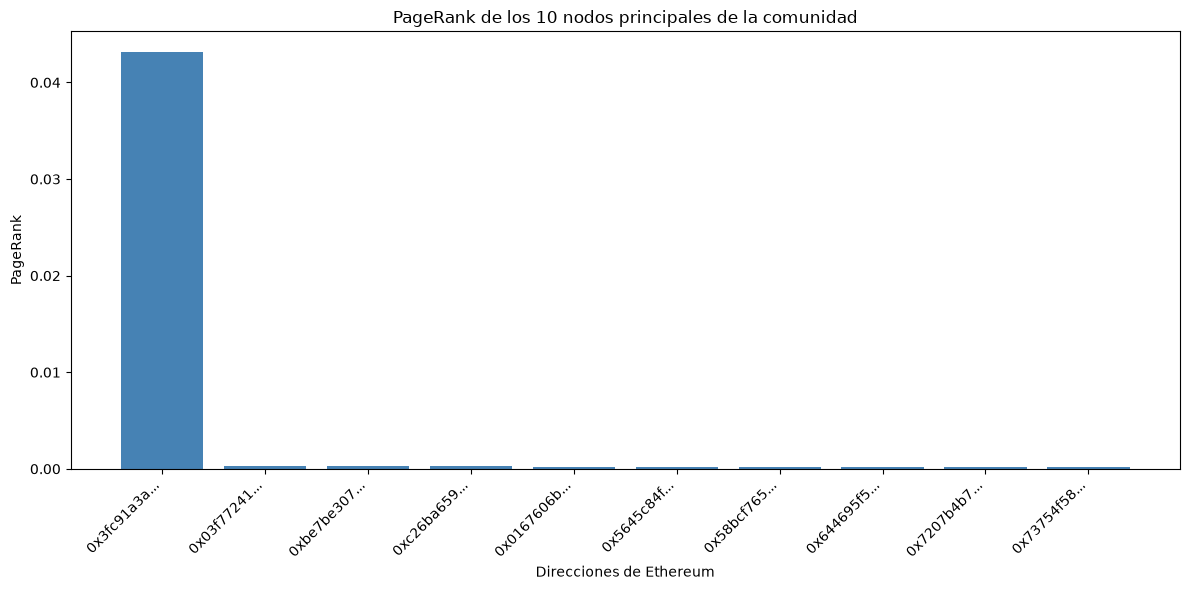

In [12]:
# Visualizar el PageRank de los 10 nodos principales

direcciones = [nodo[:10] + "..." for nodo, valor in top_10_comunidad]
valores = [valor for nodo, valor in top_10_comunidad]

plt.figure(figsize=(12, 6))

plt.bar(direcciones, valores, color="steelblue")

plt.title("PageRank de los 10 nodos principales de la comunidad")
plt.xlabel("Direcciones de Ethereum")
plt.ylabel("PageRank")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

# Guardar el gráfico actualizado
plt.savefig("Figura1_PageRank.png", dpi=300, bbox_inches="tight")

plt.show()

### Interpretación de la visualización

El gráfico presenta los valores de PageRank de las diez
direcciones principales de la comunidad más grande
detectada mediante Louvain.

Se observa que la dirección 0x3fc91a... presenta un
PageRank considerablemente superior al de las demás.

En particular, su valor es aproximadamente 130,92 veces
el de la segunda dirección, lo que evidencia una marcada
diferencia en su importancia estructural dentro de la red.

Este resultado respalda la comparación cuantitativa
realizada previamente y la interpretación proporcionada
por ChatGPT.

Sin embargo, el gráfico no permite determinar la identidad
ni la función específica de las direcciones. Para ello
sería necesario complementar el análisis con información
adicional sobre las transacciones y los contratos involucrados.

In [13]:

# ANÁLISIS DE LAS COMUNIDADES

# Calcular la modularidad
modularidad = nx.community.modularity(
    G_comunidades,
    comunidades,
    weight=None
)

# Calcular el tamaño de las cinco comunidades principales
total_top5 = sum(len(c) for c in comunidades[:5])

# Calcular el porcentaje que representan
porcentaje_top5 = (
    total_top5 / G_comunidades.number_of_nodes()
) * 100

print("ANÁLISIS DE COMUNIDADES")
print("----------------------")
print("Modularidad:", round(modularidad, 6))
print("Total de nodos en el Top 5:", total_top5)
print("Porcentaje de la red:", round(porcentaje_top5, 2), "%")

print("\nDISTRIBUCIÓN DE LAS CINCO COMUNIDADES")

for i, comunidad in enumerate(comunidades[:5], start=1):
    porcentaje = (
        len(comunidad) / G_comunidades.number_of_nodes()
    ) * 100

    print(
        f"Comunidad {i}: {len(comunidad)} nodos "
        f"({porcentaje:.2f}%)"
    )


ANÁLISIS DE COMUNIDADES
----------------------
Modularidad: 0.950693
Total de nodos en el Top 5: 1267
Porcentaje de la red: 22.54 %

DISTRIBUCIÓN DE LAS CINCO COMUNIDADES
Comunidad 1: 467 nodos (8.31%)
Comunidad 2: 357 nodos (6.35%)
Comunidad 3: 168 nodos (2.99%)
Comunidad 4: 141 nodos (2.51%)
Comunidad 5: 134 nodos (2.38%)


Calculando posiciones del grafo...


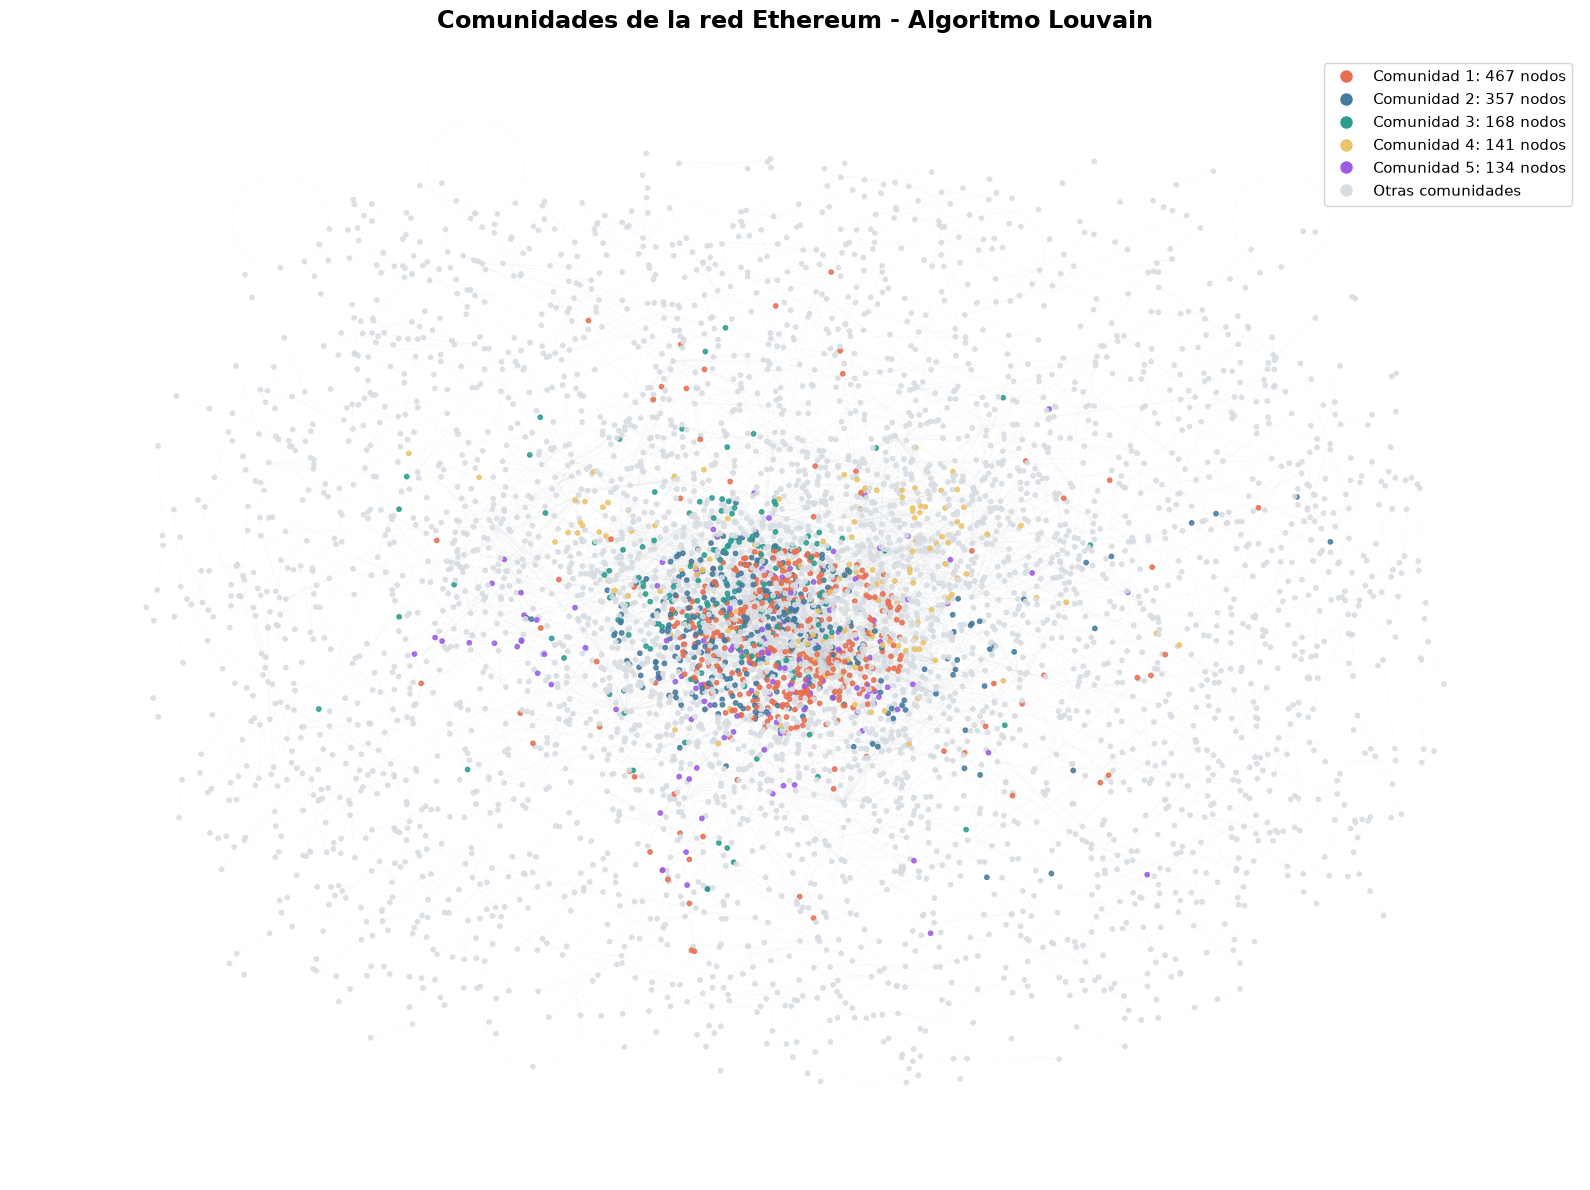

Gráfico guardado en: output\comunidades_louvain.png


In [14]:

# VISUALIZACIÓN DE COMUNIDADES

import numpy as np
from matplotlib.lines import Line2D
from pathlib import Path

# Crear la carpeta de resultados si no existe
carpeta_output = Path("output")
carpeta_output.mkdir(parents=True, exist_ok=True)

# Asignar una comunidad a cada nodo
comunidad_por_nodo = {}

for i, comunidad in enumerate(comunidades):
    for nodo in comunidad:
        comunidad_por_nodo[nodo] = i

# Colores de las cinco comunidades principales
paleta = [
    "#E76F51",  # Coral
    "#457B9D",  # Azul
    "#2A9D8F",  # Verde
    "#E9C46A",  # Amarillo
    "#9B5DE5"   # Violeta
]

# Color gris para las demás comunidades
colores_nodos = [
    paleta[comunidad_por_nodo[nodo]]
    if comunidad_por_nodo[nodo] < 5
    else "#D8DDE3"
    for nodo in G_comunidades.nodes()
]

# Posiciones de los nodos
print("Calculando posiciones del grafo...")

pos = nx.spring_layout(
    G_comunidades,
    seed=42,
    iterations=35
)

# Crear la figura
fig, ax = plt.subplots(figsize=(16, 12))

nx.draw_networkx_edges(
    G_comunidades,
    pos,
    ax=ax,
    edge_color="#AAB4BE",
    alpha=0.12,
    width=0.3
)

nx.draw_networkx_nodes(
    G_comunidades,
    pos,
    ax=ax,
    node_color=colores_nodos,
    node_size=10,
    alpha=0.85
)

# Crear la leyenda
leyenda = []

for i in range(5):
    leyenda.append(
        Line2D(
            [0], [0],
            marker="o",
            color="w",
            markerfacecolor=paleta[i],
            markersize=10,
            label=f"Comunidad {i+1}: {len(comunidades[i])} nodos"
        )
    )

leyenda.append(
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        markerfacecolor="#D8DDE3",
        markersize=10,
        label="Otras comunidades"
    )
)

ax.legend(
    handles=leyenda,
    loc="upper right",
    fontsize=11,
    frameon=True
)

ax.set_title(
    "Comunidades de la red Ethereum - Algoritmo Louvain",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.axis("off")
plt.tight_layout()

# Guardar el gráfico
ruta_grafico = carpeta_output / "comunidades_louvain.png"

plt.savefig(
    ruta_grafico,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Gráfico guardado en:", ruta_grafico)


In [15]:

# ANÁLISIS DE COMPONENTES CONECTADOS

componentes = list(
    nx.connected_components(G_comunidades)
)

componentes = sorted(
    componentes,
    key=len,
    reverse=True
)

print("ANÁLISIS DE COMPONENTES CONECTADOS")
print("----------------------------------")

print("Cantidad de componentes:", len(componentes))
print("Tamaño del componente más grande:", len(componentes[0]))

print("\nTOP 5 - COMPONENTES MÁS GRANDES")

for i, componente in enumerate(componentes[:5], start=1):
    print(
        f"Componente {i}: {len(componente)} nodos"
    )

print("\nPorcentaje en el componente más grande:")

porcentaje = (
    len(componentes[0]) / G_comunidades.number_of_nodes()
) * 100

print(f"{porcentaje:.2f}%")


ANÁLISIS DE COMPONENTES CONECTADOS
----------------------------------
Cantidad de componentes: 1156
Tamaño del componente más grande: 2799

TOP 5 - COMPONENTES MÁS GRANDES
Componente 1: 2799 nodos
Componente 2: 37 nodos
Componente 3: 35 nodos
Componente 4: 24 nodos
Componente 5: 23 nodos

Porcentaje en el componente más grande:
49.80%


In [16]:

# COMUNIDADES EN EL COMPONENTE PRINCIPAL

# Seleccionar el componente conectado más grande
nodos_principales = componentes[0]

# Identificar las comunidades que contienen nodos
# pertenecientes al componente principal
comunidades_principales = [
    comunidad.intersection(nodos_principales)
    for comunidad in comunidades
    if comunidad.intersection(nodos_principales)
]

# Ordenarlas por tamaño
comunidades_principales = sorted(
    comunidades_principales,
    key=len,
    reverse=True
)

print("COMUNIDADES EN EL COMPONENTE PRINCIPAL")
print("--------------------------------------")

print("Nodos del componente:", len(nodos_principales))
print("Comunidades encontradas:", len(comunidades_principales))

print("\nTOP 5 - COMUNIDADES DEL COMPONENTE PRINCIPAL")

for i, comunidad in enumerate(comunidades_principales[:5], start=1):
    print(f"Comunidad {i}: {len(comunidad)} nodos")

# Calcular modularidad únicamente en este componente
G_principal = G_comunidades.subgraph(
    nodos_principales
).copy()

modularidad_principal = nx.community.modularity(
    G_principal,
    comunidades_principales,
    weight=None
)

print("\nModularidad del componente principal:",
      round(modularidad_principal, 6))


COMUNIDADES EN EL COMPONENTE PRINCIPAL
--------------------------------------
Nodos del componente: 2799
Comunidades encontradas: 33

TOP 5 - COMUNIDADES DEL COMPONENTE PRINCIPAL
Comunidad 1: 467 nodos
Comunidad 2: 357 nodos
Comunidad 3: 168 nodos
Comunidad 4: 141 nodos
Comunidad 5: 134 nodos

Modularidad del componente principal: 0.898587
